In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import seaborn as sns

In [89]:
df = pd.read_csv('public/data/reviews_sentiment_analysis.csv')

In [90]:
df.head()

,index,id,date,clean_text,professor_name,department_name,course,source,attendance,exam_match,...,term,comment,professor_id,course_normal,course_clean,grading_category,cleaned_comment,sentiment_score,sentiment_label,comments
0,3,14,2021-09-05T00:34:39,🧑‍🏫 سید محمد شهرتاش\n🏫 #برق\n📒 بررسی ۱-بررسی۲-...,محمد شهرتاش,برق,بررسی ۱,فایل پاورپوینت یا پی دی اف می دهد,حضور و غیاب نمی کند,بله,...,مهر 99,چیزی اضافه ایی نیست,1,بررسی ۱-بررسی ۲-حفاظت,بررسی ۱,منصفانه/متوسط,اضافه ایی,0.000,Neutral,چیزی اضافه ایی نیست
1,3,14,2021-09-05T00:34:39,🧑‍🏫 سید محمد شهرتاش\n🏫 #برق\n📒 بررسی ۱-بررسی۲-...,محمد شهرتاش,برق,بررسی ۲,فایل پاورپوینت یا پی دی اف می دهد,حضور و غیاب نمی کند,بله,...,مهر 99,چیزی اضافه ایی نیست,1,بررسی ۱-بررسی ۲-حفاظت,بررسی ۲,منصفانه/متوسط,اضافه ایی,0.000,Neutral,چیزی اضافه ایی نیست
2,3,14,2021-09-05T00:34:39,🧑‍🏫 سید محمد شهرتاش\n🏫 #برق\n📒 بررسی ۱-بررسی۲-...,محمد شهرتاش,برق,حفاظت,فایل پاورپوینت یا پی دی اف می دهد,حضور و غیاب نمی کند,بله,...,مهر 99,چیزی اضافه ایی نیست,1,بررسی ۱-بررسی ۲-حفاظت,حفاظت,منصفانه/متوسط,اضافه ایی,0.000,Neutral,چیزی اضافه ایی نیست
3,4,15,2021-09-05T00:35:51,🧑‍🏫 دکتر هاجر فلاحتی\n🏫 #مهندسی_کامپیوتر\n📒 مد...,هاجر فلاحتی,مهندسی_کامپیوتر,مدار منطقی,یادم نمیاد,حضور مهم نیست اما تاثیر مثبت دارد,خیر,...,بهمن 98,خوب درس نمیده اصلا، نمره ها رو خوب نمیده و اصل...,655,مدار منطقی- طراحی سیستم های کامپیوتری,مدار منطقی,سخت‌گیر/بدنمره,درس نمیده اصلا نمرهها نمیده اصلا ترم اخر ترم ج...,-0.715,Negative,خوب درس نمیده اصلا، نمره ها رو خوب نمیده و اصل...
4,4,15,2021-09-05T00:35:51,🧑‍🏫 دکتر هاجر فلاحتی\n🏫 #مهندسی_کامپیوتر\n📒 مد...,هاجر فلاحتی,مهندسی_کامپیوتر,طراحی سیستم های کامپیوتری,یادم نمیاد,حضور مهم نیست اما تاثیر مثبت دارد,خیر,...,بهمن 98,خوب درس نمیده اصلا، نمره ها رو خوب نمیده و اصل...,655,مدار منطقی- طراحی سیستم های کامپیوتری,طراحی سیستم های کامپیوتری,سخت‌گیر/بدنمره,درس نمیده اصلا نمرهها نمیده اصلا ترم اخر ترم ج...,-0.715,Negative,خوب درس نمیده اصلا، نمره ها رو خوب نمیده و اصل...


In [91]:
df.columns

Index(['index', 'id', 'date', 'clean_text', 'professor_name',
       'department_name', 'course', 'source', 'attendance', 'exam_match',
       'grading', 'consistency', 'knowledge', 'delivery', 'management',
       'responsiveness', 'respect', 'contact_way', 'term', 'comment',
       'professor_id', 'course_normal', 'course_clean', 'grading_category',
       'cleaned_comment', 'sentiment_score', 'sentiment_label', 'comments'],
      dtype='object')

In [92]:
df = df[['id', 'professor_name', 'department_name', 'attendance', 'exam_match',
         'consistency', 'knowledge', 'delivery', 'management',
         'responsiveness', 'respect', 'grading_category', 'professor_id', 'sentiment_score']]

In [93]:
df = df.drop_duplicates()
df.shape

(4294, 14)

In [94]:
df = df.drop(labels='id', axis = 1)

In [95]:
df

,professor_name,department_name,attendance,exam_match,consistency,knowledge,delivery,management,responsiveness,respect,grading_category,professor_id,sentiment_score
0,محمد شهرتاش,برق,حضور و غیاب نمی کند,بله,['8'],['9'],['7'],['9'],['8'],['10'],منصفانه/متوسط,1,0.0000
3,هاجر فلاحتی,مهندسی_کامپیوتر,حضور مهم نیست اما تاثیر مثبت دارد,خیر,['1'],['2'],['1'],['3'],['2'],['10'],سخت‌گیر/بدنمره,655,-0.7150
5,علم الهدی,مهندسی_مواد,حضور و غیاب نمی کند,بله,['9'],['8'],['10'],['9'],['10'],['10'],منصفانه/متوسط,592,0.0000
6,حجت قاسمی,مکانیک,حضور و غیاب نمی کند,بله,['10'],['10'],['9'],['9'],['9'],['9'],منصفانه/متوسط,699,0.0000
7,فریبرز قاسمی,مهندسی_کامپیوتر,حضور و غیاب نمی کند,بله,['8'],['10'],['8'],['10'],['7'],['9'],منصفانه/متوسط,656,0.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4611,حمیدرضا نوشکاران,ریاضی,حضور مهم نیست اما تاثیر مثبت دارد,بله,['8'],['8'],['8'],['9'],['8'],['10'],منصفانه/متوسط,160,-0.9982
4612,عین الله خنجری,مهندسی_کامپیوتر,حضور و غیاب نمی کند,بله,['8'],['6'],['4'],['6'],['1'],['3'],سخت‌گیر/بدنمره,690,0.5359
4613,رضا انتظاری ملکی,مهندسی_کامپیوتر,حضور مهم است و تاثیر مستقیم دارد,بله,['10'],['10'],['10'],['10'],['10'],['10'],منصفانه/متوسط,666,0.9704
4614,بخشایش,مهندسی_مواد,حضور مهم است و تاثیر مستقیم دارد,بله,['10'],['10'],['10'],['10'],['10'],['10'],منصفانه/متوسط,633,0.9947


In [96]:
attendance_mapping = {
    'حضور مهم است و تاثیر مستقیم دارد': 3,      # High importance
    'حضور مهم نیست اما تاثیر مثبت دارد': 2,      # Moderate importance  
    'حضور و غیاب نمی کند': 1,                     # Low importance
    'یادم نمیاد': 0                               # Don't remember/neutral
}

# Apply the mapping
df['attendance_numeric'] = df['attendance'].map(attendance_mapping)

# Or replace the original column
df['attendance'] = df['attendance'].map(attendance_mapping)

In [97]:
exam_mapping = {
    'خیر': -1,
    'اصلا': -1,
    'اصلا و به هیچ عنوان': -1,
    'بله': 1,
    'تا حدودی': 0
}

# Apply the mapping for known values
df['exam_match'] = df['exam_match'].map(exam_mapping)

# Fill remaining values with 0
df['exam_match'] = df['exam_match'].fillna(0)

In [98]:
# Extract the number from strings like "['10']", "['9']", etc.
df['consistency'] = df['consistency'].str.extract(r'(\d+)')
# Convert to numeric
df['consistency'] = pd.to_numeric(df['consistency'])

# Extract the number from strings like "['10']", "['9']", etc.
df['knowledge'] = df['knowledge'].str.extract(r'(\d+)')
# Convert to numeric
df['knowledge'] = pd.to_numeric(df['knowledge'])

# Extract the number from strings like "['10']", "['9']", etc.
df['delivery'] = df['delivery'].str.extract(r'(\d+)')
# Convert to numeric
df['delivery'] = pd.to_numeric(df['delivery'])

# Extract the number from strings like "['10']", "['9']", etc.
df['management'] = df['management'].str.extract(r'(\d+)')
# Convert to numeric
df['management'] = pd.to_numeric(df['management'])

# Extract the number from strings like "['10']", "['9']", etc.
df['responsiveness'] = df['responsiveness'].str.extract(r'(\d+)')
# Convert to numeric
df['responsiveness'] = pd.to_numeric(df['responsiveness'])

# Extract the number from strings like "['10']", "['9']", etc.
df['respect'] = df['respect'].str.extract(r'(\d+)')
# Convert to numeric
df['respect'] = pd.to_numeric(df['respect'])

In [99]:
# Assuming order from easy to strict
grading_mapping = {
    'آسان‌گیر/خوش‌نمره': 0,        # Easy grader
    'منصفانه/متوسط': 1,            # Fair/Medium
    'غیرقابل پیش‌بینی': 2,          # Unpredictable
    'سخت‌گیر/بدنمره': 3,            # Strict grader
    'اطلاعی نیست': np.nan           # No information
}

df['grading_category'] = df['grading_category'].map(grading_mapping)

In [100]:
df

,professor_name,department_name,attendance,exam_match,consistency,knowledge,delivery,management,responsiveness,respect,grading_category,professor_id,sentiment_score,attendance_numeric
0,محمد شهرتاش,برق,1,1.0,8,9,7,9,8,10,1.0,1,0.0000,1
3,هاجر فلاحتی,مهندسی_کامپیوتر,2,-1.0,1,2,1,3,2,10,3.0,655,-0.7150,2
5,علم الهدی,مهندسی_مواد,1,1.0,9,8,10,9,10,10,1.0,592,0.0000,1
6,حجت قاسمی,مکانیک,1,1.0,10,10,9,9,9,9,1.0,699,0.0000,1
7,فریبرز قاسمی,مهندسی_کامپیوتر,1,1.0,8,10,8,10,7,9,1.0,656,0.0000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4611,حمیدرضا نوشکاران,ریاضی,2,1.0,8,8,8,9,8,10,1.0,160,-0.9982,2
4612,عین الله خنجری,مهندسی_کامپیوتر,1,1.0,8,6,4,6,1,3,3.0,690,0.5359,1
4613,رضا انتظاری ملکی,مهندسی_کامپیوتر,3,1.0,10,10,10,10,10,10,1.0,666,0.9704,3
4614,بخشایش,مهندسی_مواد,3,1.0,10,10,10,10,10,10,1.0,633,0.9947,3


In [101]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4294 entries, 0 to 4615
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   professor_name      4294 non-null   object 
 1   department_name     4294 non-null   object 
 2   attendance          4294 non-null   int64  
 3   exam_match          4294 non-null   float64
 4   consistency         4294 non-null   int64  
 5   knowledge           4294 non-null   int64  
 6   delivery            4294 non-null   int64  
 7   management          4294 non-null   int64  
 8   responsiveness      4294 non-null   int64  
 9   respect             4294 non-null   int64  
 10  grading_category    4142 non-null   float64
 11  professor_id        4294 non-null   int64  
 12  sentiment_score     4294 non-null   float64
 13  attendance_numeric  4294 non-null   int64  
dtypes: float64(3), int64(9), object(2)
memory usage: 503.2+ KB


In [102]:
# Define aggregation rules for each column
aggregation_rules = {
    # Text columns - take the longest name
    'professor_name': lambda x: max(x, key=len) if len(x) > 0 else x.iloc[0],
    
    # Text column with single value per professor
    'department_name': 'first',
    
    # Numerical columns - take the mean
    'attendance': 'mean',
    'exam_match': 'mean',
    'consistency': 'mean',
    'knowledge': 'mean',
    'delivery': 'mean',
    'management': 'mean',
    'responsiveness': 'mean',
    'respect': 'mean',
    'sentiment_score': 'mean',
    
    # Grading category - take the mode (most common)
    'grading_category': lambda x: x.mode()[0] if not x.mode().empty else x.iloc[0]
}

# keep only professors with >= 5 rows
df_filtered = df.groupby("professor_id").filter(lambda x: len(x) >= 3)
# Group by professor_id and apply aggregations
df_grouped = df_filtered.groupby("professor_id", as_index=False).agg(aggregation_rules)

print(f"Original shape: {df.shape}")
print(f"Filtered shape (>=5 repeats): {df_filtered.shape}")
print(f"Grouped shape: {df_grouped.shape}")

Original shape: (4294, 14)
Filtered shape (>=5 repeats): (3778, 14)
Grouped shape: (409, 13)


In [103]:
df_grouped.head()

,professor_id,professor_name,department_name,attendance,exam_match,consistency,knowledge,delivery,management,responsiveness,respect,sentiment_score,grading_category
0,3,علیرضا نظام الحسینی عز آبادی,برق,1.000000,0.750000,9.250000,9.750000,9.000000,9.500000,10.000000,10.000000,0.729925,1.0
1,4,ادیب ابریشمی فر,برق,0.888889,-0.222222,8.555556,9.000000,7.333333,7.555556,7.777778,7.222222,0.239211,0.0
2,5,احمد چلداوی,برق,1.333333,-0.333333,7.000000,7.333333,6.333333,7.000000,8.000000,8.333333,0.212400,3.0
3,6,ابوذر غفاری,برق,2.000000,-0.125000,9.125000,9.875000,8.125000,6.500000,7.750000,9.250000,-0.025825,1.0
4,7,شاهرخ فرهمند,برق,1.200000,0.200000,8.800000,9.600000,8.800000,7.200000,9.200000,9.600000,0.391560,0.0


In [104]:
# 1. Prepare the data for clustering
# Select only numerical columns for clustering
numerical_cols = ['attendance', 'exam_match', 'consistency', 'knowledge', 
                  'delivery', 'management', 'responsiveness', 'respect', 
                  'sentiment_score', 'grading_category']


In [105]:
# Create feature matrix
X = df_grouped[numerical_cols].copy()

# Handle any missing values
X = X.fillna(X.mean())

print(f"Data shape for clustering: {X.shape}")
print(f"Features used: {numerical_cols}")


Data shape for clustering: (409, 10)
Features used: ['attendance', 'exam_match', 'consistency', 'knowledge', 'delivery', 'management', 'responsiveness', 'respect', 'sentiment_score', 'grading_category']


In [106]:

# 2. Scale the data (important for K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# K-means

In [107]:
sil_scores = []
K_range = range(2, 11)  # check k from 2 to 10

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    sil_scores.append(score)
    print(f"k={k}, silhouette score={score:.4f}")


k=2, silhouette score=0.3993
k=3, silhouette score=0.2610
k=4, silhouette score=0.2369
k=5, silhouette score=0.2063
k=6, silhouette score=0.2031
k=7, silhouette score=0.1598
k=8, silhouette score=0.1856
k=9, silhouette score=0.1538
k=10, silhouette score=0.1470


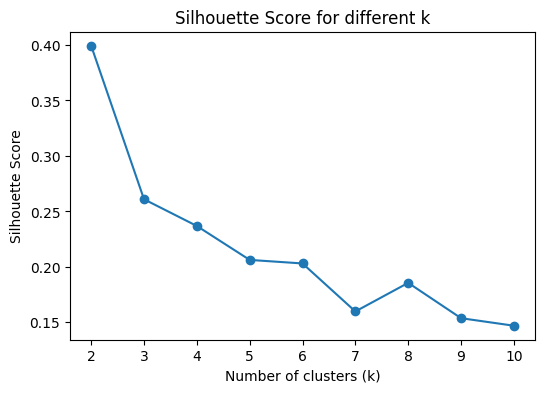

In [108]:
plt.figure(figsize=(6,4))
plt.plot(K_range, sil_scores, '-o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for different k')
plt.show()


In [109]:
optimal_k = 2
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
df_grouped['cluster'] = kmeans.fit_predict(X_scaled)


# Apply PCA (2D)

In [110]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

df_pca = df_grouped.copy()
df_pca["PC1"] = X_pca[:, 0]
df_pca["PC2"] = X_pca[:, 1]

In [86]:
import plotly.express as px
import plotly.express as px

def plott_interactive():
    fig = px.scatter(
        df_pca,
        x="PC1",
        y="PC2",
        hover_name="professor_name",      # shows name only on hover
        color=df_pca["cluster"].astype(str),  # optional: color by cluster
        opacity=0.5
    )

    fig.update_layout(
        title="PCA of Professors (Interactive)",
        xaxis_title="PC1",
        yaxis_title="PC2",
        showlegend=True
    )

    fig.show()


In [87]:
plott_interactive()

In [116]:
df_unsupervised = df_pca.copy()
df_unsupervised.to_csv('unsupervised_analysis.csv', index=False, encoding='utf-8-sig')